# Question D: When do citations peak, and which papers become "high hitters"?

## Identify peak timing using Kaplan–Meier approach

**Question:** How many years after publication do FSR papers typically peak?

**Framing:** we treat "time to citation peak" as a *duration / survival-analysis* problem rather than a plain descriptive statistic. This is deliberate:

- Papers published recently may not have peaked yet — we simply don't know their peak age. This is **right-censoring**, and a plain mean/median over *observed* peak ages would be biased downward if we ignored it (we'd be systematically excluding papers whose true peak lies further in the future).
- Kaplan–Meier (KM) is the standard non-parametric way to estimate a time-to-event distribution in the presence of censoring, and it lets us report **quantiles** (e.g. median peak age) with a defensible estimator rather than an ad-hoc average.


### 1.1 Setup

For each paper $i = 1, \dots, N$ define:

- $T_i$: the **age at citation peak** (years since publication) — the *event time*, if observed.
- $C_i$: the **censoring time** — for papers that have not yet had the chance to peak (e.g. published too recently, or still on a rising citation trajectory as of the data cut-off), this is how long we've been able to observe them so far.
- $\delta_i \in \{0, 1\}$: event indicator, $\delta_i = 1$ if the peak was actually observed, $\delta_i = 0$ if the paper is censored (we only know it hasn't peaked by $C_i$).
- Observed duration: $X_i = \min(T_i, C_i)$.

So each paper contributes a pair $(X_i, \delta_i)$ to the estimator.

### 1.2 The Kaplan–Meier estimator

Let $t_{(1)} < t_{(2)} < \dots < t_{(k)}$ be the distinct observed **event** times (i.e. distinct peak ages actually seen in the data, ignoring censoring times). At each event time $t_{(j)}$ define:

- $n_j$ = number of papers still **at risk** just before $t_{(j)}$ (i.e. not yet peaked and not yet censored — durations $\geq t_{(j)}$),
- $d_j$ = number of papers whose peak is observed exactly at $t_{(j)}$.

The Kaplan–Meier estimator of the **survival function** — here, the probability that a paper has *not yet peaked* by time $t$ — is:

$$
\hat S(t) \;=\; \prod_{j:\, t_{(j)} \le t} \left(1 - \frac{d_j}{n_j}\right)
$$

with $\hat S(t) = 1$ for $t$ before the first event. $\hat S(t)$ is a step function that starts at 1 and drops at each observed peak time; it only ever drops at *event* times, not at censoring times (censored papers simply leave the risk set).

### 1.3 Getting the quantile we actually want

The $p$-th quantile of the peak-age distribution, $t_p$, is defined directly from the estimated survival curve as

$$
t_p \;=\; \inf\{\, t : \hat S(t) \le 1-p \,\}
$$

So the **median peak age** is

$$
t_{0.5} \;=\; \inf\{\, t : \hat S(t) \le 0.5 \,\}
$$

i.e. the first time at which the estimated fraction of papers that have *not yet* peaked drops to (or below) 50%. We'll pull this — and the 25th/75th percentiles for a spread — directly off the fitted KM curve.

*(Variance / confidence intervals on $\hat S(t)$ use Greenwood's formula, which `lifelines` computes automatically; we report the CI bands on the quantiles for completeness.)*


In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lifelines import KaplanMeierFitter

plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.grid"] = True


### 1.4 Data

Two files, both expected in the same folder as this notebook:

- **`fsr_citations_by_year_openalex.csv`** — long format, one row per (paper, citation year): `doi`, `fsr_pub_year`, `citation_year`, `years_since_pub`, `cites_that_year`, `source`. This is what lets us build a yearly citation curve per paper.
- **`master_dataset.csv`** — one row per paper (Scopus export): includes `doi`, `year` (publication year), `cited_by` (total citations), plus metadata. This gives us the *full* paper roster, including papers with zero citations that never show up in the citations-by-year file at all.

A few real quirks in this data that the pipeline below handles explicitly:

1. **Duplicate sources.** Each (doi, citation_year) can appear twice — once tagged `openalex` and once `openalex_citing_works` — from two different OpenAlex pulls. They agree ~99.5% of the time where both exist, so we keep one (`openalex` preferred) rather than double-counting.
2. **Negative `years_since_pub`.** A handful of rows have citations dated *before* the paper's recorded publication year (preprint/working-paper artifacts). These are dropped — they're not valid "age since publication" observations.
3. **The current year is partial.** Today is mid-September 2026, so 2026 citation counts are incomplete and would make very recent papers look like they've already "peaked" and declined, when really the year just isn't over. We therefore treat **2025 as the last complete year** and don't use 2026 counts at all when identifying peaks.
4. **Zero-citation papers.** ~60% of papers in `master_dataset.csv` never appear in the citations file at all — OpenAlex found no citing works for them. These aren't "peaked at age 0"; they simply haven't been cited (yet), so they're included as **censored at their current age**, not as an observed event.

**Censoring rule actually used:** a paper's peak is only counted as *observed* ($\delta_i=1$) if we've seen at least one full year *after* the annual-citation maximum — i.e. we've had the chance to see it decline (or at least plateau) and it's still the max. If the maximum citation year is the very last year we can observe (or the paper has zero citations to date), we don't yet know if it's still rising, so it's **right-censored** at its current age.


In [18]:
LAST_COMPLETE_YEAR = 2025  # 2026 is only partially observed as of this data pull (mid-Sept 2026)

cit = pd.read_csv("fsr_citations_by_year_openalex.csv")
master = pd.read_csv("master_dataset.csv")

# 1) Dedup the two OpenAlex sources for the same (doi, citation_year); keep 'openalex' when both exist.
cit = cit[cit["source"] == "openalex_citing_works"]  # 'openalex' sorts before 'openalex_citing_works

# 2) Drop invalid ages and the incomplete current year.
cit = cit[(cit["years_since_pub"] >= 0) & (cit["citation_year"] <= LAST_COMPLETE_YEAR)]

# 3) Full paper roster: every FSR paper with a DOI and a valid, complete publication age.
#    (master_dataset.csv also contains two other journals -- restrict to Financial Services Review.)
master_fsr = master[master["source_title"] == "Financial Services Review"]
papers = (master_fsr.dropna(subset=["doi"])
                 .drop_duplicates(subset="doi")[["doi", "year"]]
                 .rename(columns={"year": "pub_year"}))
papers = papers[papers["pub_year"] <= LAST_COMPLETE_YEAR].copy()
papers["current_age"] = LAST_COMPLETE_YEAR - papers["pub_year"]

# 4) Per-paper annual citation counts, keyed by (doi, age).
annual = cit.groupby(["doi", "years_since_pub"])["cites_that_year"].sum().reset_index()
annual_lookup = annual.set_index(["doi", "years_since_pub"])["cites_that_year"]

def peak_and_event(doi, current_age):
    """Build the full 0..current_age citation series (missing years = 0 citations),
    then apply the censoring rule from the markdown above."""
    series = np.zeros(current_age + 1)
    for age in range(current_age + 1):
        series[age] = annual_lookup.get((doi, age), 0)
    total = series.sum()
    if total == 0:
        return current_age, 0                     # never cited yet -> censored
    peak_age = int(np.argmax(series))              # first max in case of ties
    if peak_age < current_age:
        return peak_age, 1                         # decline observed after the peak -> event
    return current_age, 0                          # peak sits at the edge of observation -> censored

results = [peak_and_event(row.doi, row.current_age) for row in papers.itertuples()]
papers["peak_age"], papers["peaked"] = zip(*results)

df = papers.rename(columns={"peak_age": "peak_age"})[["doi", "pub_year", "current_age", "peak_age", "peaked"]]
print(f"Papers included: {len(df)}")
df.head()

Papers included: 616


,doi,pub_year,current_age,peak_age,peaked
0,10.2139/ssrn.3272486,2020,5,5,0
1,10.61190/fsr.v25i2.3218,2016,9,1,1
2,10.61190/fsr.v23i2.3133,2014,11,7,1
3,10.61190/fsr.v32i4.3355,2024,1,1,0
4,10.61190/fsr.v22i4.4661,2013,12,12,0


### 1.5 Fit the Kaplan–Meier estimator

N papers: 616
Censoring rate (not yet peaked): 39.0%


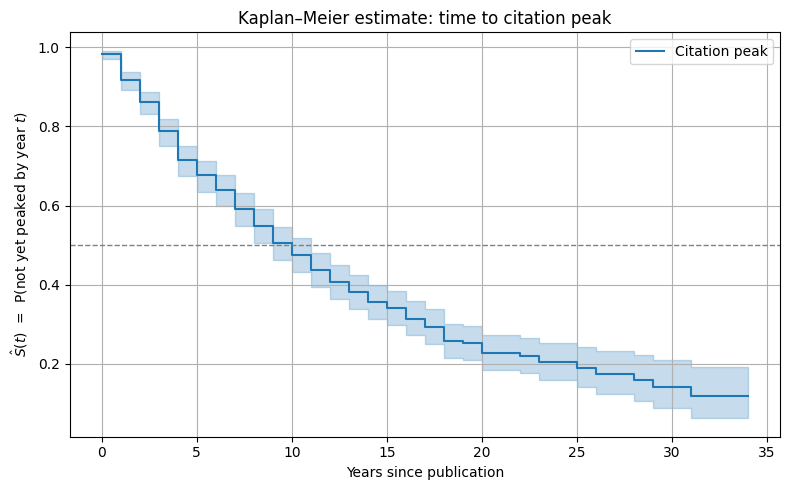

In [19]:
kmf = KaplanMeierFitter()
kmf.fit(durations=df["peak_age"], event_observed=df["peaked"], label="Citation peak")

censoring_rate = 1 - df["peaked"].mean()
print(f"N papers: {len(df)}")
print(f"Censoring rate (not yet peaked): {censoring_rate:.1%}")

ax = kmf.plot_survival_function(ci_show=True)
ax.set_xlabel("Years since publication")
ax.set_ylabel(r"$\hat{S}(t)$  =  P(not yet peaked by year $t$)")
ax.set_title("Kaplan–Meier estimate: time to citation peak")
plt.axhline(0.5, color="gray", linestyle="--", linewidth=1)
plt.tight_layout()
plt.show()


### 1.6 Quantiles of peak age

In [20]:
# --- Convenience: built-in lifelines quantile lookups ---
median_peak_age = kmf.median_survival_time_
ci_median = kmf.confidence_interval_survival_function_

print(f"Median peak age (t_0.5): {median_peak_age:.2f} years")

quantile_levels = [0.25, 0.50, 0.75]
# lifelines wants 1-p as the "percentile" of S(t); .values.ravel() flattens its (n,1) DataFrame output
quantile_ages = kmf.percentile(1 - np.array(quantile_levels)).values.ravel()

quantile_table = pd.DataFrame({
    "quantile (p)": quantile_levels,
    "peak_age (years)": quantile_ages
})
quantile_table


Median peak age (t_0.5): 10.00 years


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/lifelines/fitters/__init__.py:279: ApproximationWarning: Approximating using `survival_function_`. To increase accuracy, try using or increasing the resolution of the timeline kwarg in `.fit(..., timeline=timeline)`.

  warnings.warn(


,quantile (p),peak_age (years)
0,0.25,4.0
1,0.50,10.0
2,0.75,20.0


# Question D, part 2: which papers become "high hitters"?

**Question:** Which paper-level factors are associated with higher total citation counts, once we account for the fact that older papers have simply had more time to accrue them?

**Approach:** a Negative Binomial regression of total citations on paper-level covariates, with publication age entered as an **offset** — i.e. we model the citation *rate per year of exposure*, not raw totals, so a coefficient reflects "this variable shifts citations per year," not "this variable correlates with being an old paper."


## 2.1 Model

Citation counts are non-negative integers, over-dispersed relative to a Poisson (a small number of papers get disproportionately many citations — the "high hitters" the question asks about), so Negative Binomial is the standard choice over plain Poisson.

For paper $i$, let $Y_i$ be total citations, $\text{age}_i$ years since publication, and $\mathbf{x}_i$ the paper-level covariates (author count, page length, etc.):

$$
Y_i \sim \text{NegBin}(\mu_i, \alpha)
$$

$$
\log(\mu_i) \;=\; \underbrace{\log(\text{age}_i)}_{\text{offset}} \;+\; \beta_0 + \boldsymbol{\beta}^\top \mathbf{x}_i
$$

Equivalently:

$$
\mathbb{E}[Y_i \mid \mathbf{x}_i] \;=\; \text{age}_i \cdot \exp(\beta_0 + \boldsymbol{\beta}^\top \mathbf{x}_i), \qquad \text{Var}(Y_i) = \mu_i + \alpha \mu_i^2
$$

An **offset** is a covariate whose coefficient is fixed at exactly 1, rather than estimated — so $\log(\text{age}_i)$ is *forced* into the linear predictor with coefficient 1, which is the same as saying "expected total citations scale linearly with age," and everything else in $\mathbf{x}_i$ is then interpreted as shifting the **citation rate per year**, not the raw total.

Each $\exp(\beta_j)$ is an **incidence rate ratio (IRR)**: multiply the yearly citation rate by $\exp(\beta_j)$ for a one-unit increase in $x_j$, holding age and everything else fixed.

### A check the offset assumption needs before we trust it

Forcing the age coefficient to exactly 1 assumes citations accrue *linearly* with age — one extra year always buys the same number of extra citations, no matter the paper's age. That's a strong assumption, and it's directly in tension with the peak-and-decline shape found in Part 1 of this question (citations rise, peak, then decline — not a straight line). So before committing to the offset, we fit `log(age)` as a **free** covariate in a second model and check whether its estimated coefficient actually comes out close to 1. If it does, the offset is a reasonable simplification for this sample; if it doesn't, the offset version's other coefficients should be treated cautiously.


In [21]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
import warnings

# statsmodels' NegativeBinomial likelihood throws a benign divide-by-zero warning
# at endog=0 rows during internal log() calls; it doesn't affect the fitted result.
warnings.filterwarnings("ignore", category=RuntimeWarning)

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")


## 2.2 Data & feature engineering

Source: `master_dataset.csv`, filtered to Financial Services Review (it also contains two other journals — see Part 1).

None of the covariates below exist as ready-made columns; they're derived from the raw fields:

| Feature | Derivation |
|---|---|
| `n_authors` | count of `;`-separated entries in `authors_id` |
| `n_affiliations` | count of `;`-separated entries in `affiliations` |
| `n_keywords` | count of `;`-separated entries in `author_keywords` (0 if missing) |
| `page_length` | `page_end - page_start` |
| `abstract_length` | word count of `abstract` |
| `pub_year_c` | `year`, mean-centered — controls for calendar-era effects (see Part 1: the citing literature grew ~7.5x over the sample period, independent of paper age) |
| `age` | years since publication as of the last complete data year |

`document_type` was checked and dropped — every FSR paper in this dataset is coded `"Article"`, so it carries no information.

Rows with missing `page_start`/`page_end` (5 papers) or `cited_by` are dropped, since those can't be used to build `page_length` or the outcome.


In [22]:
LAST_COMPLETE_YEAR = 2025

master = pd.read_csv("master_dataset.csv")
fsr = master[master["source_title"] == "Financial Services Review"].copy()

fsr["n_authors"]       = fsr["authors_id"].str.split(";").str.len()
fsr["n_affiliations"]  = fsr["affiliations"].fillna("").str.split(";").str.len()
fsr["n_keywords"]      = fsr["author_keywords"].fillna("").apply(lambda s: len(s.split(";")) if s else 0)
fsr["page_length"]     = fsr["page_end"] - fsr["page_start"]
fsr["abstract_length"] = fsr["abstract"].fillna("").str.split().str.len()
fsr["age"]             = LAST_COMPLETE_YEAR - fsr["year"]
fsr["pub_year_c"]      = fsr["year"] - fsr["year"].mean()

fsr = fsr[fsr["age"] > 0].dropna(subset=["cited_by", "page_length"]).copy()
fsr["log_age"] = np.log(fsr["age"])

print(f"document_type unique values: {fsr['document_type'].nunique()}  (dropped -- no variation)")
print(f"Papers in model: {len(fsr)}")
fsr[["n_authors", "n_affiliations", "n_keywords", "page_length",
     "abstract_length", "age", "cited_by"]].describe()


document_type unique values: 1  (dropped -- no variation)
Papers in model: 582


,n_authors,n_affiliations,n_keywords,page_length,abstract_length,age,cited_by
count,582.0000,582.0000,582.0000,582.0000,582.0000,582.0000,582.0000
mean,2.2251,1.7371,3.1392,16.2199,122.6598,16.8144,15.1409
std,0.9198,0.8243,1.9074,5.3468,38.1295,8.9128,43.7554
min,1.0000,1.0000,0.0000,1.0000,3.0000,1.0000,0.0000
25%,2.0000,1.0000,2.0000,13.0000,106.0000,10.0000,2.0000
50%,2.0000,2.0000,3.0000,16.0000,113.0000,17.0000,5.0000
75%,3.0000,2.0000,4.0000,19.0000,128.0000,24.0000,12.0000
max,7.0000,6.0000,11.0000,41.0000,453.0000,34.0000,678.0000


## 2.3 Fit: does the offset assumption hold?

In [23]:
feat_cols = ["n_authors", "n_affiliations", "n_keywords",
             "page_length", "abstract_length", "pub_year_c"]

y = fsr["cited_by"].to_numpy()
X = sm.add_constant(fsr[feat_cols])

# --- free-age model: log(age) as an ordinary covariate, coefficient estimated ---
X_free = sm.add_constant(fsr[["log_age"] + feat_cols])
model_free = sm.NegativeBinomial(y, X_free)
res_free = model_free.fit(disp=0)

age_coef = res_free.params["log_age"]
age_ci = res_free.conf_int().loc["log_age"]
print(f"Estimated log(age) coefficient: {age_coef:.3f}   95% CI [{age_ci[0]:.3f}, {age_ci[1]:.3f}]")
print("Offset assumption (coefficient == 1) is", 
      "reasonable -- 1 falls inside the CI." if age_ci[0] <= 1 <= age_ci[1]
      else "NOT well supported -- 1 falls outside the CI; treat the offset model's coefficients with caution.")


Estimated log(age) coefficient: 1.039   95% CI [0.647, 1.430]
Offset assumption (coefficient == 1) is reasonable -- 1 falls inside the CI.


## 2.4 Main model: age as a fixed offset

In [24]:
offset = np.log(fsr["age"].to_numpy())

model_offset = sm.NegativeBinomial(y, X, offset=offset)
res_offset = model_offset.fit(disp=0)
print(res_offset.summary())


                     NegativeBinomial Regression Results                      
Dep. Variable:                      y   No. Observations:                  582
Model:               NegativeBinomial   Df Residuals:                      575
Method:                           MLE   Df Model:                            6
Date:                Mon, 14 Sep 2026   Pseudo R-squ.:                0.006137
Time:                        21:43:23   Log-Likelihood:                -2008.9
converged:                       True   LL-Null:                       -2021.3
Covariance Type:            nonrobust   LLR p-value:                 0.0003706
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
const              -0.2759      0.342     -0.807      0.420      -0.946       0.394
n_authors           0.2162      0.079      2.732      0.006       0.061       0.371
n_affiliations     -0.1711      

## 2.5 Which variable contributes most?

Raw coefficients aren't directly comparable across variables — `n_authors` moves in units of 1 author, `abstract_length` in units of 1 word, so a bigger raw coefficient doesn't mean a bigger real-world effect. Two complementary views:

- **Incidence rate ratios (IRR)**: $\exp(\beta_j)$, the actual multiplicative effect of a one-unit change — the natural units to report and interpret.
- **Standardized coefficients**: $\beta_j \times \text{sd}(x_j)$, which puts every variable on the same footing (effect of a one-*standard-deviation* change), so they can be ranked against each other for "which contributes most."


In [25]:
irr = np.exp(res_offset.params[feat_cols]).rename("IRR")
pvals = res_offset.pvalues[feat_cols].rename("p-value")
std_effect = (res_offset.params[feat_cols] * fsr[feat_cols].std()).rename("standardized effect")

summary_table = pd.concat([irr, std_effect, pvals], axis=1)
summary_table["abs_std_effect"] = summary_table["standardized effect"].abs()
summary_table = summary_table.sort_values("abs_std_effect", ascending=False).drop(columns="abs_std_effect")
summary_table


,IRR,standardized effect,p-value
page_length,1.0405,0.2124,0.0019
n_authors,1.2413,0.1988,0.0063
abstract_length,0.9952,-0.1817,0.0014
n_affiliations,0.8427,-0.1410,0.0615
pub_year_c,1.0076,0.0678,0.3840
n_keywords,0.9785,-0.0414,0.5294


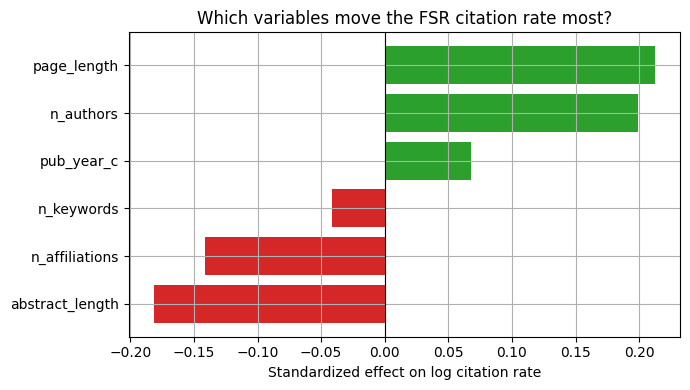

In [26]:
fig, ax = plt.subplots(figsize=(7, 4))
ordered = summary_table["standardized effect"].sort_values()
colors = ["#d62728" if v < 0 else "#2ca02c" for v in ordered]
ax.barh(ordered.index, ordered.values, color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Standardized effect on log citation rate")
ax.set_title("Which variables move the FSR citation rate most?")
plt.tight_layout()
plt.show()


## 2.7 Do these factors actually distinguish high hitters?

**Definition:** a "high hitter" is a paper in the **top 10% by total citations** (`cited_by`) within FSR. This is a fixed cutoff on the raw count, so — unlike the NB model's rate-based coefficients above — it does *not* automatically adjust for age: an old paper needs less of a citation *rate* to land in the top 10% by raw count than a young paper does, so some of what separates high hitters here is simply age, not the content-level factors.

To check whether the NB model already built in §2.4 also picks out these same papers: flag a paper as a **model-predicted high hitter** if its fitted $\hat\mu_i$ is in the top 10%, and compare that against the actual top-10% label. The decision threshold is set at the **90th percentile of $\hat\mu_i$**, matching the 10% base rate — with a 90/10 imbalanced label, a flat 0.5 probability cutoff would predict almost nobody as a high hitter and give a degenerate confusion matrix.


In [27]:
threshold_actual = fsr["cited_by"].quantile(0.90)
fsr["high_hitter"] = (fsr["cited_by"] >= threshold_actual).astype(int)
print(f"High-hitter cutoff: >= {threshold_actual:.0f} citations "
      f"({fsr['high_hitter'].sum()} of {len(fsr)} papers, {fsr['high_hitter'].mean():.1%})")


High-hitter cutoff: >= 26 citations (63 of 582 papers, 10.8%)


### 2.7.1 Confusion matrix — NB model's fitted values vs. actual high hitters

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score

fsr["nb_fitted"] = res_offset.predict(X, offset=offset)
nb_threshold = fsr["nb_fitted"].quantile(0.90)
fsr["nb_pred_high"] = (fsr["nb_fitted"] >= nb_threshold).astype(int)

cm_nb = confusion_matrix(fsr["high_hitter"], fsr["nb_pred_high"])
tn, fp, fn, tp = cm_nb.ravel()

print("Confusion matrix (rows = actual, cols = predicted):")
print(pd.DataFrame(cm_nb, index=["actual: not high hitter", "actual: high hitter"],
                    columns=["pred: not high hitter", "pred: high hitter"]))
print(f"\nTP={tp}  FP={fp}  TN={tn}  FN={fn}")
print(f"\n{classification_report(fsr['high_hitter'], fsr['nb_pred_high'], digits=2)}")

# Accuracy (0.84 below) is misleading with a 90/10 imbalance -- a model that never predicts
# "high hitter" would already score 0.90. AUC is threshold-free and the more honest summary.
auc_nb = roc_auc_score(fsr["high_hitter"], fsr["nb_fitted"])
print(f"AUC (threshold-free): {auc_nb:.3f}")


Confusion matrix (rows = actual, cols = predicted):
                         pred: not high hitter  pred: high hitter
actual: not high hitter                    473                 46
actual: high hitter                         50                 13

TP=13  FP=46  TN=473  FN=50

              precision    recall  f1-score   support

           0       0.90      0.91      0.91       519
           1       0.22      0.21      0.21        63

    accuracy                           0.84       582
   macro avg       0.56      0.56      0.56       582
weighted avg       0.83      0.84      0.83       582

